In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
BASE_DIR = "/content/drive/MyDrive/inter_IIT/Task_2/"

In [ ]:
!pip install -q ultralytics opencv-python pillow psutil pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 5.7 MB/s eta 0:00:00


In [ ]:
import os
import re
import time
import json
import platform
import psutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from ultralytics import YOLO

In [ ]:
system_info = {
    "cpu": platform.processor(),
    "logical_cores": os.cpu_count(),
    "opencv_threads": CPU_THREADS,
    "ram_gb": round(
        psutil.virtual_memory().total / (1024**3),
        2
    ),
    "python": platform.python_version(),
    "opencv": cv2.__version__,
}

print(json.dumps(
    system_info,
    indent=2
))

{
  "cpu": "x86_64",
  "logical_cores": 2,
  "opencv_threads": 1,
  "ram_gb": 12.67,
  "python": "3.13.15",
  "opencv": "5.0.0"
}


In [ ]:
MODEL_NAME = "yolov8n.pt"

model = YOLO(MODEL_NAME)

print("Model loaded successfully.")

Model loaded successfully.


In [ ]:
model_path = MODEL_NAME

model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

print(f"Model file size: {model_size_mb:.2f} MB")

Model file size: 6.25 MB


In [ ]:
total_params = sum(p.numel() for p in model.model.parameters())

print(f"Total parameters: {total_params:,}")
print(f"Parameters: {total_params / 1e6:.2f} M")

Total parameters: 3,157,200
Parameters: 3.16 M


In [ ]:
def parse_instruction(instruction):
    """
    Parse simple natural-language editing instructions.

    Returns:
        {
            "operation": "remove" or "replace",
            "target": str,
            "replacement": str or None
        }
    """

    text = instruction.lower().strip()

    # Replacement patterns
    replacement_patterns = [
        r"(?:replace|change|turn)\s+(?:the\s+)?(.+?)\s+(?:with|to|into)\s+(?:a\s+|an\s+|the\s+)?(.+)",
    ]

    for pattern in replacement_patterns:
        match = re.search(pattern, text)

        if match:
            target = match.group(1).strip()
            replacement = match.group(2).strip()

            return {
                "operation": "replace",
                "target": target,
                "replacement": replacement
            }

    # Removal patterns
    removal_patterns = [
        r"(?:remove|delete|erase)\s+(?:the\s+)?(.+)",
    ]

    for pattern in removal_patterns:
        match = re.search(pattern, text)

        if match:
            target = match.group(1).strip()

            return {
                "operation": "remove",
                "target": target,
                "replacement": None
            }

    raise ValueError(
        "Could not parse instruction. "
        "Use formats such as 'remove the car' or "
        "'replace the car with a bicycle'."
    )

In [ ]:
parse_instruction("remove the bike and replace the bike with car")

{'operation': 'replace', 'target': 'bike', 'replacement': 'car'}

In [ ]:
tests = [
    "Remove the car",
    "Delete the dog",
    "Erase the person",
    "Replace the car with a bicycle",
    "Change the dog to a cat"
]

for instruction in tests:
    try:
        result = parse_instruction(instruction)
        print(instruction)
        print(" -> ", result)
        print()
    except Exception as e:
        print("Error:", e)

Remove the car
 ->  {'operation': 'remove', 'target': 'car', 'replacement': None}

Delete the dog
 ->  {'operation': 'remove', 'target': 'dog', 'replacement': None}

Erase the person
 ->  {'operation': 'remove', 'target': 'person', 'replacement': None}

Replace the car with a bicycle
 ->  {'operation': 'replace', 'target': 'car', 'replacement': 'bicycle'}

Change the dog to a cat
 ->  {'operation': 'replace', 'target': 'dog', 'replacement': 'cat'}



In [ ]:
COCO_CLASSES = model.names

print("Number of supported classes:", len(COCO_CLASSES))
print(list(COCO_CLASSES.values())[:20])

Number of supported classes: 80
['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow']


In [ ]:
def normalize_target(target):
    """
    Convert simple phrases such as
    'red car' -> 'car'
    'large dog' -> 'dog'
    """

    words_to_remove = {
        "red", "blue", "green", "yellow", "black", "white",
        "small", "large", "big", "little",
        "the", "a", "an"
    }

    words = target.lower().split()

    remaining = [
        word for word in words
        if word not in words_to_remove
    ]

    return " ".join(remaining)

In [ ]:
def find_class_id(target):
    target = normalize_target(target)

    for class_id, class_name in COCO_CLASSES.items():
        if class_name.lower() == target:
            return class_id

    return None

In [ ]:
COCO_CLASSES[find_class_id('a blue car')]

'car'

In [ ]:
for target in ["car", "dog", "red car", "large dog", "bicycle"]:
    print(target, "->", find_class_id(target))

car -> 2
dog -> 16
red car -> 2
large dog -> 16
bicycle -> 1


In [ ]:
def detect_target(
    image,
    target,
    confidence=0.25,
    imgsz=640
):
    """
    Detect the requested target using YOLOv8n.

    Returns:
        list of dictionaries containing bounding boxes,
        confidence and class name.
    """

    class_id = find_class_id(target)

    if class_id is None:
        raise ValueError(
            f"'{target}' is not available in the E0 COCO class vocabulary."
        )

    results = model.predict(
        source=image,
        device=DEVICE,
        conf=confidence,
        imgsz=imgsz,
        verbose=False
    )

    detections = []

    result = results[0]

    if result.boxes is None:
        return detections

    for box in result.boxes:
        detected_class = int(box.cls.item())

        if detected_class != class_id:
            continue

        xyxy = box.xyxy[0].cpu().numpy()

        detections.append({
            "bbox": xyxy.astype(int),
            "confidence": float(box.conf.item()),
            "class": COCO_CLASSES[detected_class]
        })

    return detections

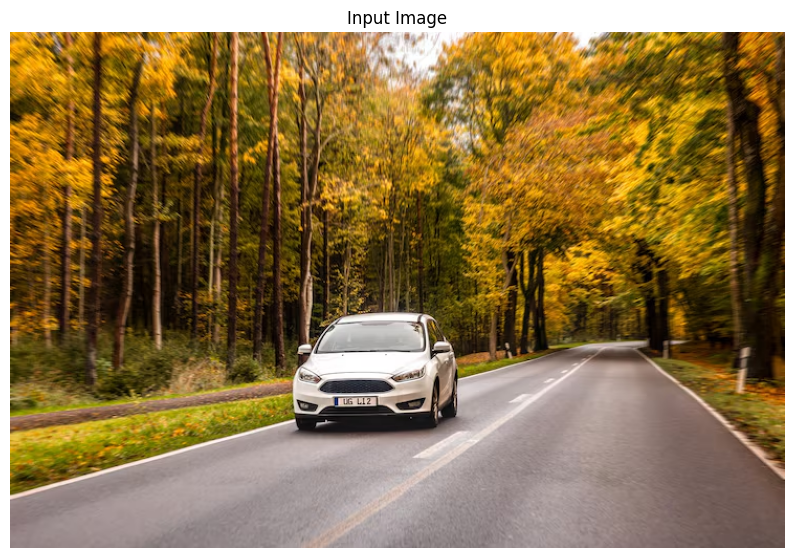

In [ ]:
IMAGE_PATH = "car.jpg"

image = cv2.imread(IMAGE_PATH)

if image is None:
    raise FileNotFoundError(f"Could not read {IMAGE_PATH}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Input Image")
plt.show()

In [ ]:
def draw_detections(image, detections):
    output = image.copy()

    for det in detections:
        x1, y1, x2, y2 = det["bbox"]
        confidence = det["confidence"]
        label = det["class"]

        cv2.rectangle(
            output,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        text = f"{label}: {confidence:.2f}"

        cv2.putText(
            output,
            text,
            (x1, max(20, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

    return output

Instruction: Remove the car
Parsed: {'operation': 'remove', 'target': 'car', 'replacement': None}
Detections: [{'bbox': array([267, 267, 429, 381]), 'confidence': 0.9229576587677002, 'class': 'car'}]


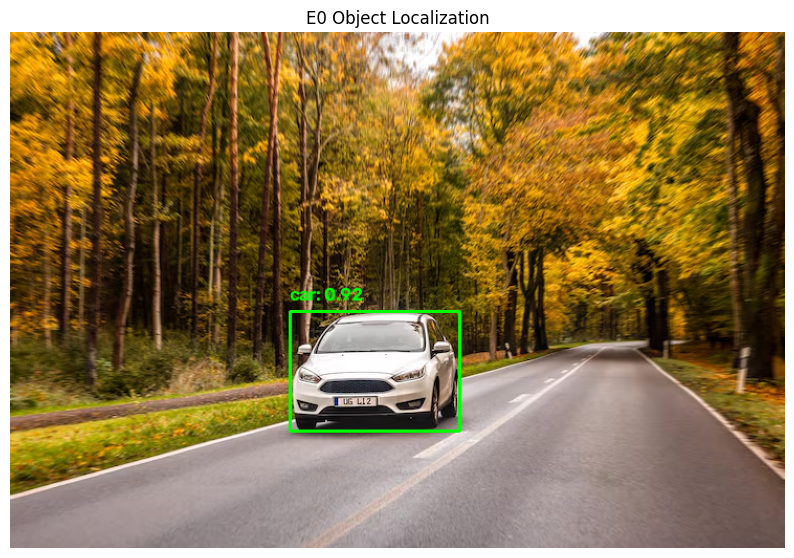

In [ ]:
instruction = "Remove the car"

parsed = parse_instruction(instruction)

detections = detect_target(
    image,
    parsed["target"]
)

print("Instruction:", instruction)
print("Parsed:", parsed)
print("Detections:", detections)

visualized = draw_detections(image, detections)

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(visualized, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("E0 Object Localization")
plt.show()

In [ ]:
def bbox_to_mask(image, bbox, dilation=5):
    """
    Convert bounding box into binary mask.
    """

    h, w = image.shape[:2]

    x1, y1, x2, y2 = bbox

    x1 = max(0, min(w - 1, x1))
    x2 = max(0, min(w, x2))

    y1 = max(0, min(h - 1, y1))
    y2 = max(0, min(h, y2))

    mask = np.zeros((h, w), dtype=np.uint8)

    mask[y1:y2, x1:x2] = 255

    if dilation > 0:
        kernel = np.ones(
            (dilation, dilation),
            np.uint8
        )

        mask = cv2.dilate(
            mask,
            kernel,
            iterations=1
        )

    return mask

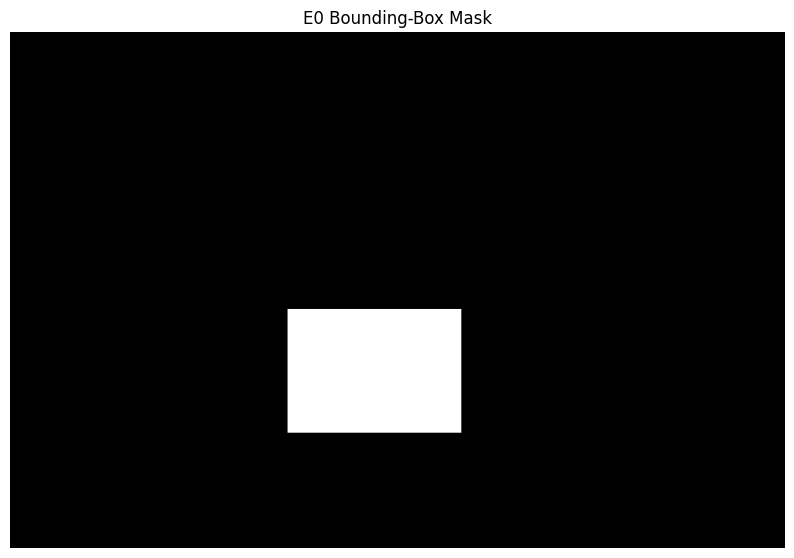

In [ ]:
if len(detections) == 0:
    raise RuntimeError("Target object was not detected.")

bbox = detections[0]["bbox"]

mask = bbox_to_mask(
    image,
    bbox
)

plt.figure(figsize=(10, 7))
plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.title("E0 Bounding-Box Mask")
plt.show()

In [ ]:
def remove_object_opencv(
    image,
    mask,
    radius=5,
    method="telea"
):
    if method.lower() == "telea":
        inpaint_method = cv2.INPAINT_TELEA

    elif method.lower() == "ns":
        inpaint_method = cv2.INPAINT_NS

    else:
        raise ValueError(
            "method must be 'telea' or 'ns'"
        )

    result = cv2.inpaint(
        image,
        mask,
        radius,
        inpaint_method
    )

    return result

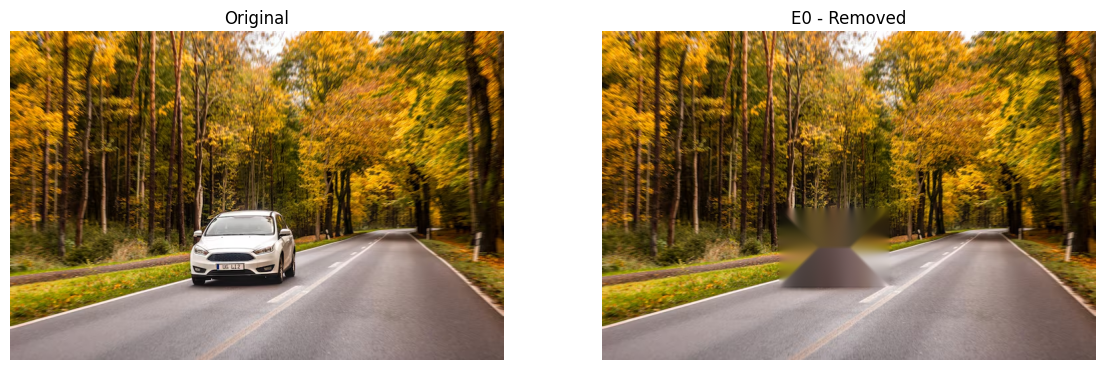

In [ ]:
removed = remove_object_opencv(
    image,
    mask,
    radius=5,
    method="telea"
)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(removed, cv2.COLOR_BGR2RGB))
plt.title("E0 - Removed")
plt.axis("off")

plt.show()

In [ ]:
!pip install -q scikit-image

In [ ]:
import cv2
import numpy as np

from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

In [ ]:
def evaluate_removal(
    prediction,
    ground_truth,
    mask
):
    """
    Evaluate only the edited region.

    prediction:
        model output

    ground_truth:
        clean image without object

    mask:
        binary mask indicating edited region
    """

    # Ensure binary mask
    mask = mask > 0

    # Extract pixels from edited region
    pred_pixels = prediction[mask]
    gt_pixels = ground_truth[mask]

    # -------------------------
    # PSNR
    # -------------------------
    mse = np.mean(
        (pred_pixels.astype(np.float32)
         - gt_pixels.astype(np.float32)) ** 2
    )

    if mse == 0:
        psnr = float("inf")
    else:
        psnr = 10 * np.log10(
            (255.0 ** 2) / mse
        )

    # -------------------------
    # SSIM
    # -------------------------

    ys, xs = np.where(mask)

    y1, y2 = ys.min(), ys.max()
    x1, x2 = xs.min(), xs.max()

    pred_crop = prediction[
        y1:y2+1,
        x1:x2+1
    ]

    gt_crop = ground_truth[
        y1:y2+1,
        x1:x2+1
    ]

    ssim = structural_similarity(
        cv2.cvtColor(
            pred_crop,
            cv2.COLOR_BGR2GRAY
        ),
        cv2.cvtColor(
            gt_crop,
            cv2.COLOR_BGR2GRAY
        ),
        data_range=255
    )

    return {
        "PSNR_dB": psnr,
        "SSIM": ssim
    }

In [ ]:
metrics = evaluate_removal(
    removed,
    image,
    mask
)

print(metrics)

{'PSNR_dB': np.float32(7.8024817), 'SSIM': np.float64(0.15066505903141894)}


In [ ]:
def e0_remove(
    image,
    instruction,
    confidence=0.25,
    imgsz=640
):
    start = time.perf_counter()

    parsed = parse_instruction(instruction)

    if parsed["operation"] != "remove":
        raise ValueError(
            "Instruction is not a removal instruction."
        )

    detection_start = time.perf_counter()

    detections = detect_target(
        image,
        parsed["target"],
        confidence=confidence,
        imgsz=imgsz
    )

    detection_time = time.perf_counter() - detection_start

    if len(detections) == 0:
        raise RuntimeError(
            f"Could not detect target: {parsed['target']}"
        )

    # Select highest confidence detection
    best_detection = max(
        detections,
        key=lambda x: x["confidence"]
    )

    mask = bbox_to_mask(
        image,
        best_detection["bbox"]
    )

    inpaint_start = time.perf_counter()

    output = remove_object_opencv(
        image,
        mask
    )

    inpaint_time = time.perf_counter() - inpaint_start

    total_time = time.perf_counter() - start

    metadata = {
        "instruction": instruction,
        "operation": parsed["operation"],
        "target": parsed["target"],
        "bbox": best_detection["bbox"].tolist(),
        "confidence": best_detection["confidence"],
        "detection_time_sec": detection_time,
        "inpainting_time_sec": inpaint_time,
        "total_time_sec": total_time
    }

    return output, mask, metadata

In [ ]:
image_2 = cv2.imread("car_2.jpg")
output_2, mask_2, metadata_2 = e0_remove(
    image_2,
    "Remove the car"
)

print(json.dumps(metadata_2, indent=2))

{
  "instruction": "Remove the car",
  "operation": "remove",
  "target": "car",
  "bbox": [
    111,
    300,
    332,
    446
  ],
  "confidence": 0.9326183199882507,
  "detection_time_sec": 0.14160930100024416,
  "inpainting_time_sec": 0.1173310300000594,
  "total_time_sec": 0.25932860400007485
}


In [ ]:
def plot_output(image, mask, output):
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Input")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title("E0 Output")
    plt.axis("off")

    plt.show()

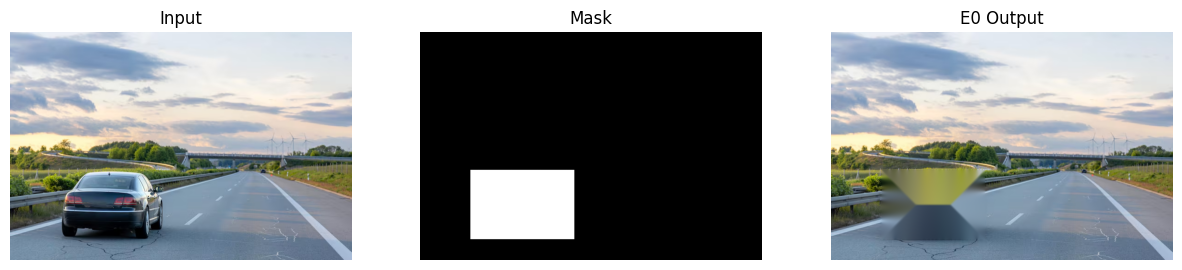

In [ ]:
plot_output(image_2, mask_2, output_2)

## Replacement

In [1]:
def place_reference_object(
    image,
    bbox,
    reference_path,
    scale=0.85
):
    reference = load_rgba_image(
        reference_path
    )

    reference = resize_reference_to_bbox(
        reference,
        bbox,
        scale=scale
    )

    x1, y1, x2, y2 = bbox

    bbox_width = x2 - x1
    bbox_height = y2 - y1

    ref_h, ref_w = reference.shape[:2]

    # Center reference object inside bbox
    x = x1 + (bbox_width - ref_w) // 2
    y = y1 + (bbox_height - ref_h) // 2

    output = image.copy()

    output = alpha_blend(
        output,
        reference,
        x,
        y
    )

    return output

In [ ]:
import os
REFERENCE_DIR = "assets/"

def get_reference_path(replacement):
    """
    Automatically find the reference image corresponding
    to the replacement object.

    Example:
        bicycle -> assets/bicycle.png
        dog     -> assets/dog.png
    """

    replacement = replacement.lower().strip()

    # Remove common articles
    replacement = replacement.replace("a ", "")
    replacement = replacement.replace("an ", "")
    replacement = replacement.replace("the ", "")

    # Normalize spaces
    replacement = replacement.strip()

    # Direct path
    reference_path = os.path.join(
        REFERENCE_DIR,
        f"{replacement}.png"
    )

    if os.path.exists(reference_path):
        return reference_path

    # Try jpg/jpeg as fallback
    for ext in [".jpg", ".jpeg", ".webp"]:
        path = os.path.join(
            REFERENCE_DIR,
            replacement + ext
        )

        if os.path.exists(path):
            return path

    raise FileNotFoundError(
        f"No reference image found for "
        f"'{replacement}'. Expected something like: "
        f"{REFERENCE_DIR}/{replacement}.png"
    )

In [ ]:
def e0_replace(
    image,
    instruction,
    scale=0.85
):
    """
    E0 replacement pipeline.

    Reuses the existing e0_remove() function:
        1. Parse replacement instruction
        2. Remove target object using e0_remove()
        3. Use the same detected bounding box
        4. Insert a reference replacement object
    """

    start = time.perf_counter()

    parsed = parse_instruction(instruction)

    if parsed["operation"] != "replace":
        raise ValueError(
            "Expected a replacement instruction, e.g. "
            "'Replace the car with a bicycle'."
        )

    target = parsed["target"]
    replacement = parsed["replacement"]

    reference_path = get_reference_path(
        replacement
    )


    removal_instruction = f"Remove the {target}"

    background, mask, removal_metadata = e0_remove(
        image,
        removal_instruction
    )

    bbox = np.array(
        removal_metadata["bbox"],
        dtype=int
    )

    output = place_reference_object(
        background,
        bbox,
        reference_path,
        scale=scale
    )

    total_time = time.perf_counter() - start

    metadata = {
        "instruction": instruction,
        "operation": "replace",
        "target": target,
        "replacement": replacement,

        "bbox": bbox.tolist(),

        "detection_confidence":
            removal_metadata["confidence"],

        "detection_time_sec":
            removal_metadata["detection_time_sec"],

        "removal_inpainting_time_sec":
            removal_metadata["inpainting_time_sec"],

        "total_time_sec":
            total_time
    }

    return output, mask, metadata

In [ ]:
instruction = "Replace the person with dog"
park_image = cv2.imread("park_2.jpg")

output, mask, metadata = e0_replace(
    park_image,
    instruction
)

In [ ]:
def plot_replacement(image, mask, output):
  plt.figure(figsize=(15, 5))

  plt.subplot(1, 3, 1)
  plt.imshow(
      cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
  )
  plt.title("Original")
  plt.axis("off")

  plt.subplot(1, 3, 2)
  plt.imshow(mask, cmap="gray")
  plt.title("Car Mask")
  plt.axis("off")

  plt.subplot(1, 3, 3)
  plt.imshow(
      cv2.cvtColor(output, cv2.COLOR_BGR2RGB)
  )
  plt.title("E0 Reference Replacement")
  plt.axis("off")

  plt.show()

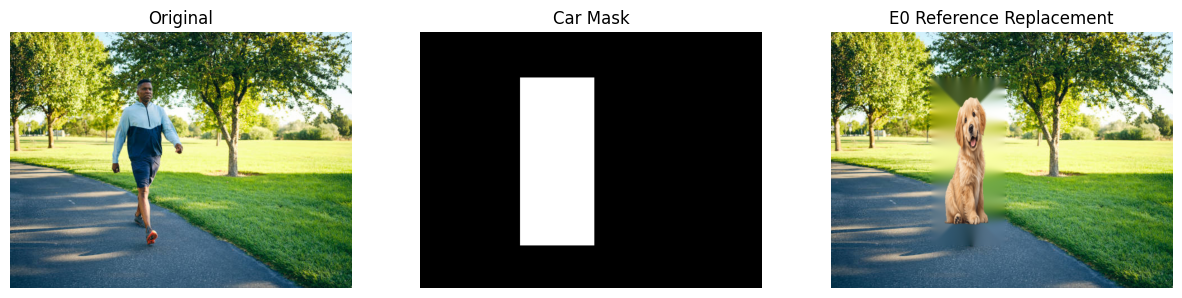

In [ ]:
plot_replacement(park_image, mask, output)

In [ ]:
def benchmark_e0(
    benchmark_cases,
    iterations=10,
    warmup=3,
    save_path="benchmarks/e0_benchmark.csv"
):
    """
    Benchmark E0 removal and replacement pipeline.

    benchmark_cases format:

    [
        {
            "image": "examples/car_2.jpg",
            "instruction": "Remove the car",
            "operation": "remove"
        },
        {
            "image": "examples/car_2.jpg",
            "instruction": "Replace the car with a bicycle",
            "operation": "replace"
        }
    ]

    Returns:
        pandas.DataFrame
    """

    os.makedirs(
        os.path.dirname(save_path),
        exist_ok=True
    )

    results = []

    print("=" * 70)
    print("E0 CPU BENCHMARK")
    print("=" * 70)

    for case in benchmark_cases:

        image_path = case["image"]
        instruction = case["instruction"]
        operation = case["operation"]

        image = cv2.imread(image_path)

        if image is None:
            print(f"Skipping: {image_path}")
            continue

        height, width = image.shape[:2]

        print(f"\nImage      : {os.path.basename(image_path)}")
        print(f"Resolution : {width} x {height}")
        print(f"Operation  : {operation}")
        print(f"Instruction: {instruction}")

        # ------------------------------------------------
        # Select pipeline
        # ------------------------------------------------
        if operation == "remove":

            pipeline = lambda: e0_remove(
                image,
                instruction
            )

        elif operation == "replace":

            pipeline = lambda: e0_replace(
                image,
                instruction
            )

        else:
            raise ValueError(
                f"Unknown operation: {operation}"
            )

        # ------------------------------------------------
        # Warmup
        # ------------------------------------------------
        print(f"Warmup: {warmup} runs...")

        for _ in range(warmup):
            pipeline()

        # ------------------------------------------------
        # Actual benchmark
        # ------------------------------------------------
        total_times = []

        for _ in range(iterations):

            start = time.perf_counter()

            pipeline()

            elapsed = time.perf_counter() - start

            total_times.append(elapsed)

        # ------------------------------------------------
        # Statistics
        # ------------------------------------------------
        mean_time = np.mean(total_times)
        median_time = np.median(total_times)
        std_time = np.std(total_times)
        min_time = np.min(total_times)
        max_time = np.max(total_times)

        result = {
            "image": os.path.basename(image_path),
            "width": width,
            "height": height,
            "resolution": f"{width}x{height}",
            "operation": operation,
            "instruction": instruction,

            "iterations": iterations,

            "mean_latency_sec":
                float(mean_time),

            "median_latency_sec":
                float(median_time),

            "std_latency_sec":
                float(std_time),

            "min_latency_sec":
                float(min_time),

            "max_latency_sec":
                float(max_time),

            "mean_latency_ms":
                float(mean_time * 1000),

            "model_size_MB":
                float(model_size_mb),

            "parameters_M":
                float(total_params / 1e6)
        }

        results.append(result)

        print(
            f"Mean latency   : {mean_time * 1000:.2f} ms"
        )
        print(
            f"Median latency : {median_time * 1000:.2f} ms"
        )

    # ------------------------------------------------
    # Create dataframe
    # ------------------------------------------------
    benchmark_df = pd.DataFrame(results)

    # ------------------------------------------------
    # Save results
    # ------------------------------------------------
    benchmark_df.to_csv(
        save_path,
        index=False
    )

    print("\n" + "=" * 70)
    print(f"Benchmark saved to: {save_path}")
    print("=" * 70)

    return benchmark_df

In [ ]:
benchmark_cases = [
    {
        "image": "car_2.jpg",
        "instruction": "Remove the car",
        "operation": "remove"
    },
    {
        "image": "park_2.jpg",
        "instruction": "Remove the person",
        "operation": "remove"
    },
    {
        "image": "road_2.jpg",
        "instruction": "Remove the bicycle",
        "operation": "remove"
    },
    {
        "image": "car.jpg",
        "instruction": "Replace the car with a bicycle",
        "operation": "replace"
    }
]

In [ ]:
e0_benchmark = benchmark_e0(
    benchmark_cases,
    iterations=10,
    warmup=3,
    save_path= BASE_DIR + "benchmarks/e0_benchmark.csv"
)

E0 CPU BENCHMARK

Image      : car_2.jpg
Resolution : 740 x 493
Operation  : remove
Instruction: Remove the car
Warmup: 3 runs...
Mean latency   : 349.77 ms
Median latency : 260.14 ms

Image      : park_2.jpg
Resolution : 612 x 459
Operation  : remove
Instruction: Remove the person
Warmup: 3 runs...
Mean latency   : 280.55 ms
Median latency : 278.00 ms

Image      : road_2.jpg
Resolution : 640 x 640
Operation  : remove
Instruction: Remove the bicycle
Warmup: 3 runs...
Mean latency   : 330.47 ms
Median latency : 328.56 ms

Image      : car.jpg
Resolution : 740 x 493
Operation  : replace
Instruction: Replace the car with a bicycle
Warmup: 3 runs...
Mean latency   : 380.26 ms
Median latency : 406.79 ms

Benchmark saved to: /content/drive/MyDrive/inter_IIT/Task_2/benchmarks/e0_benchmark.csv
